Dataset shape: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000   

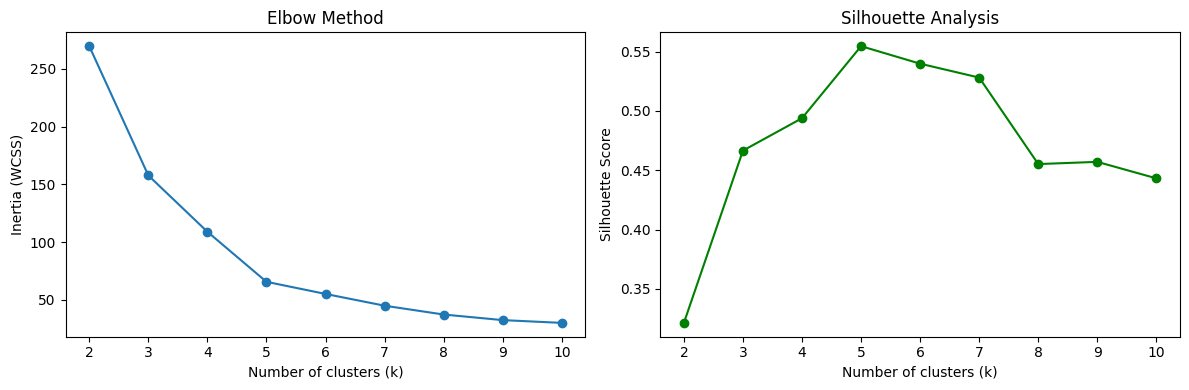


Customers per cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
Final silhouette score: 0.555


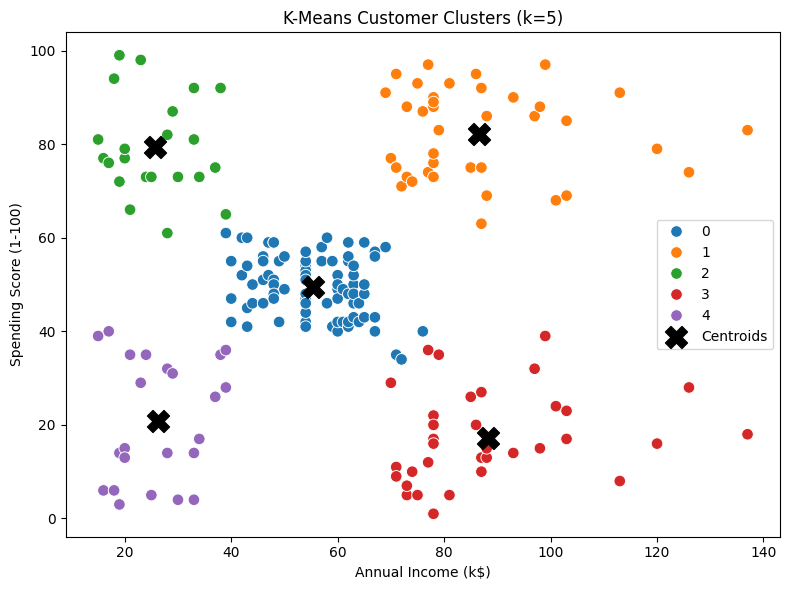


Cluster-wise customer characteristics:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


df = pd.read_csv('Mall_Customers.csv')
print("Dataset shape:", df.shape)
print(df.head())
print(df.describe())
print("Missing values:", df.isnull().sum().sum())


features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


k_values = range(2, 11)

inertias = []
silhouettes = []

for k in k_values:

    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)

    score = silhouette_score(X_scaled, labels)
    silhouettes.append(score)

    print(
        f"k={k:2d} "
        f"inertia={km.inertia_:10.2f} "
        f"silhouette={score:.3f}"
    )

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(k_values), inertias, marker='o')
ax[0].set_xlabel("Number of clusters (k)")
ax[0].set_ylabel("Inertia (WCSS)")
ax[0].set_title("Elbow Method")

ax[1].plot(
    list(k_values),
    silhouettes,
    marker='o',
    color='green'
)

ax[1].set_xlabel("Number of clusters (k)")
ax[1].set_ylabel("Silhouette Score")
ax[1].set_title("Silhouette Analysis")

plt.tight_layout()
plt.show()


best_k = 5

kmeans = KMeans(
    n_clusters=best_k,
    n_init=10,
    random_state=42
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nCustomers per cluster:")
print(df["Cluster"].value_counts().sort_index())

final_score = silhouette_score(X_scaled, df["Cluster"])

print("Final silhouette score:", round(final_score, 3))



centroids = scaler.inverse_transform(
    kmeans.cluster_centers_
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x=features[0],
    y=features[1],
    hue="Cluster",
    palette="tab10",
    s=70
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    c="black",
    label="Centroids"
)

plt.title(f"K-Means Customer Clusters (k={best_k})")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.tight_layout()
plt.show()


print("\nCluster-wise customer characteristics:")

print(
    df.groupby("Cluster")[features]
    .mean()
    .round(2)
)
